# TP 逐轮兑现分析

固定来源：2026-10-19 12:20–13:20 Asia/Shanghai 的12场，14轮实际REPAIR，其中9轮先TP。NORMAL保持不变；本次只分析历史，未修改策略。

原始腿浮盈 = 最终实际开仓数量 × 持仓方向mid − 实际开仓成本。仅观测到补仓首笔MATCHED之前；不是全账户实际逐时仓位，也不把峰值当成可成交PnL。报价配对收益按同一数量、实际开仓成本与限价计算；三轮反向残仓成本和结算另行保留。

In [1]:
import json, hashlib
from pathlib import Path
from decimal import Decimal as D
from IPython.display import display, Markdown
OUT = Path('/home/ubuntu/poly-maker/docs/development/reviews/20261019_repair_tp_path_review_1220_1320')
s=json.loads((OUT/'summary.json').read_text())
paths=json.loads((OUT/'price_paths.json').read_text())
tp=[e for e in s['episodes'] if e['first_tp']]
for src in json.loads((OUT/'source_manifest.json').read_text()):
    assert hashlib.sha256(Path(src['source']).read_bytes()).hexdigest()==src['sha256']
assert len(tp)==9 and len(s['episodes'])==14
assert s['stats']['max_unmapped_path_batches']==0
print('12 unchanged source hashes; 14 episodes, 9 TP-first; all raw path batches mapped.')

12 unchanged source hashes; 14 episodes, 9 TP-first; all raw path batches mapped.


## 逐轮收益

首次TP、已记录峰值、首张实际TP报价下的配对收益、实际配对收益分开列示。

In [2]:
table='|市场|开仓窗口|首次TP浮盈|峰值|首张TP报价配对收益|最终配对收益|\n|---|---|---:|---:|---:|---:|\n'
for e in tp:
    values=[e['market'],e['opening_window'].split(':')[-1],e['first_tp']['mark_pnl'],e['peak_original_leg_mark']['original_leg_mark_pnl'],e['first_tp_post']['paired_pnl_at_quote'],e['actual_paired_pnl']]
    table+='| '+' | '.join(str(x) for x in values)+' |\n'
display(Markdown(table))

|市场|开仓窗口|首次TP浮盈|峰值|首张TP报价配对收益|最终配对收益|
|---|---|---:|---:|---:|---:|
| 12:20 | w2 | 0.02029992 | 0.050749800 | 0.07443304 | 0.02706656000 |
| 12:25 | w2 | 0.125000 | 0.225000 | 0.300000 | -0.200000 |
| 12:25 | w13 | 0.050000 | 0.075000 | -0.200000 | -1.000000 |
| 12:30 | w4 | 0.025000 | 0.175000 | 0.150000 | 0.150000 |
| 12:40 | w1 | 0.04994276 | 0.923942810 | 0.8490285200000000000000000000 | 0.8490285200 |
| 12:45 | w4 | 0.075000 | 0.075000 | 0.250000 | -1.100000 |
| 12:55 | w22 | 0.150000 | 0.425000 | 0.500000 | 0.100000 |
| 13:10 | w1 | 0.025000 | 0.025000 | 0.000000 | 0.000000 |
| 13:15 | w12 | 0.075000 | 0.275000 | 0.300000 | 0.300000 |


## TP 路径

统一横轴为首次TP条件点之后的秒数，统一纵轴为USDC。曲线是原始腿估值，横向虚线是首张TP报价收益，菱形为实际配对收益；它们不是同一个会计量。SL竖线是历史条件点，POST竖线是实际下单时点。所有时点均在本地观察坐标中投影，非交易所撮合时刻。

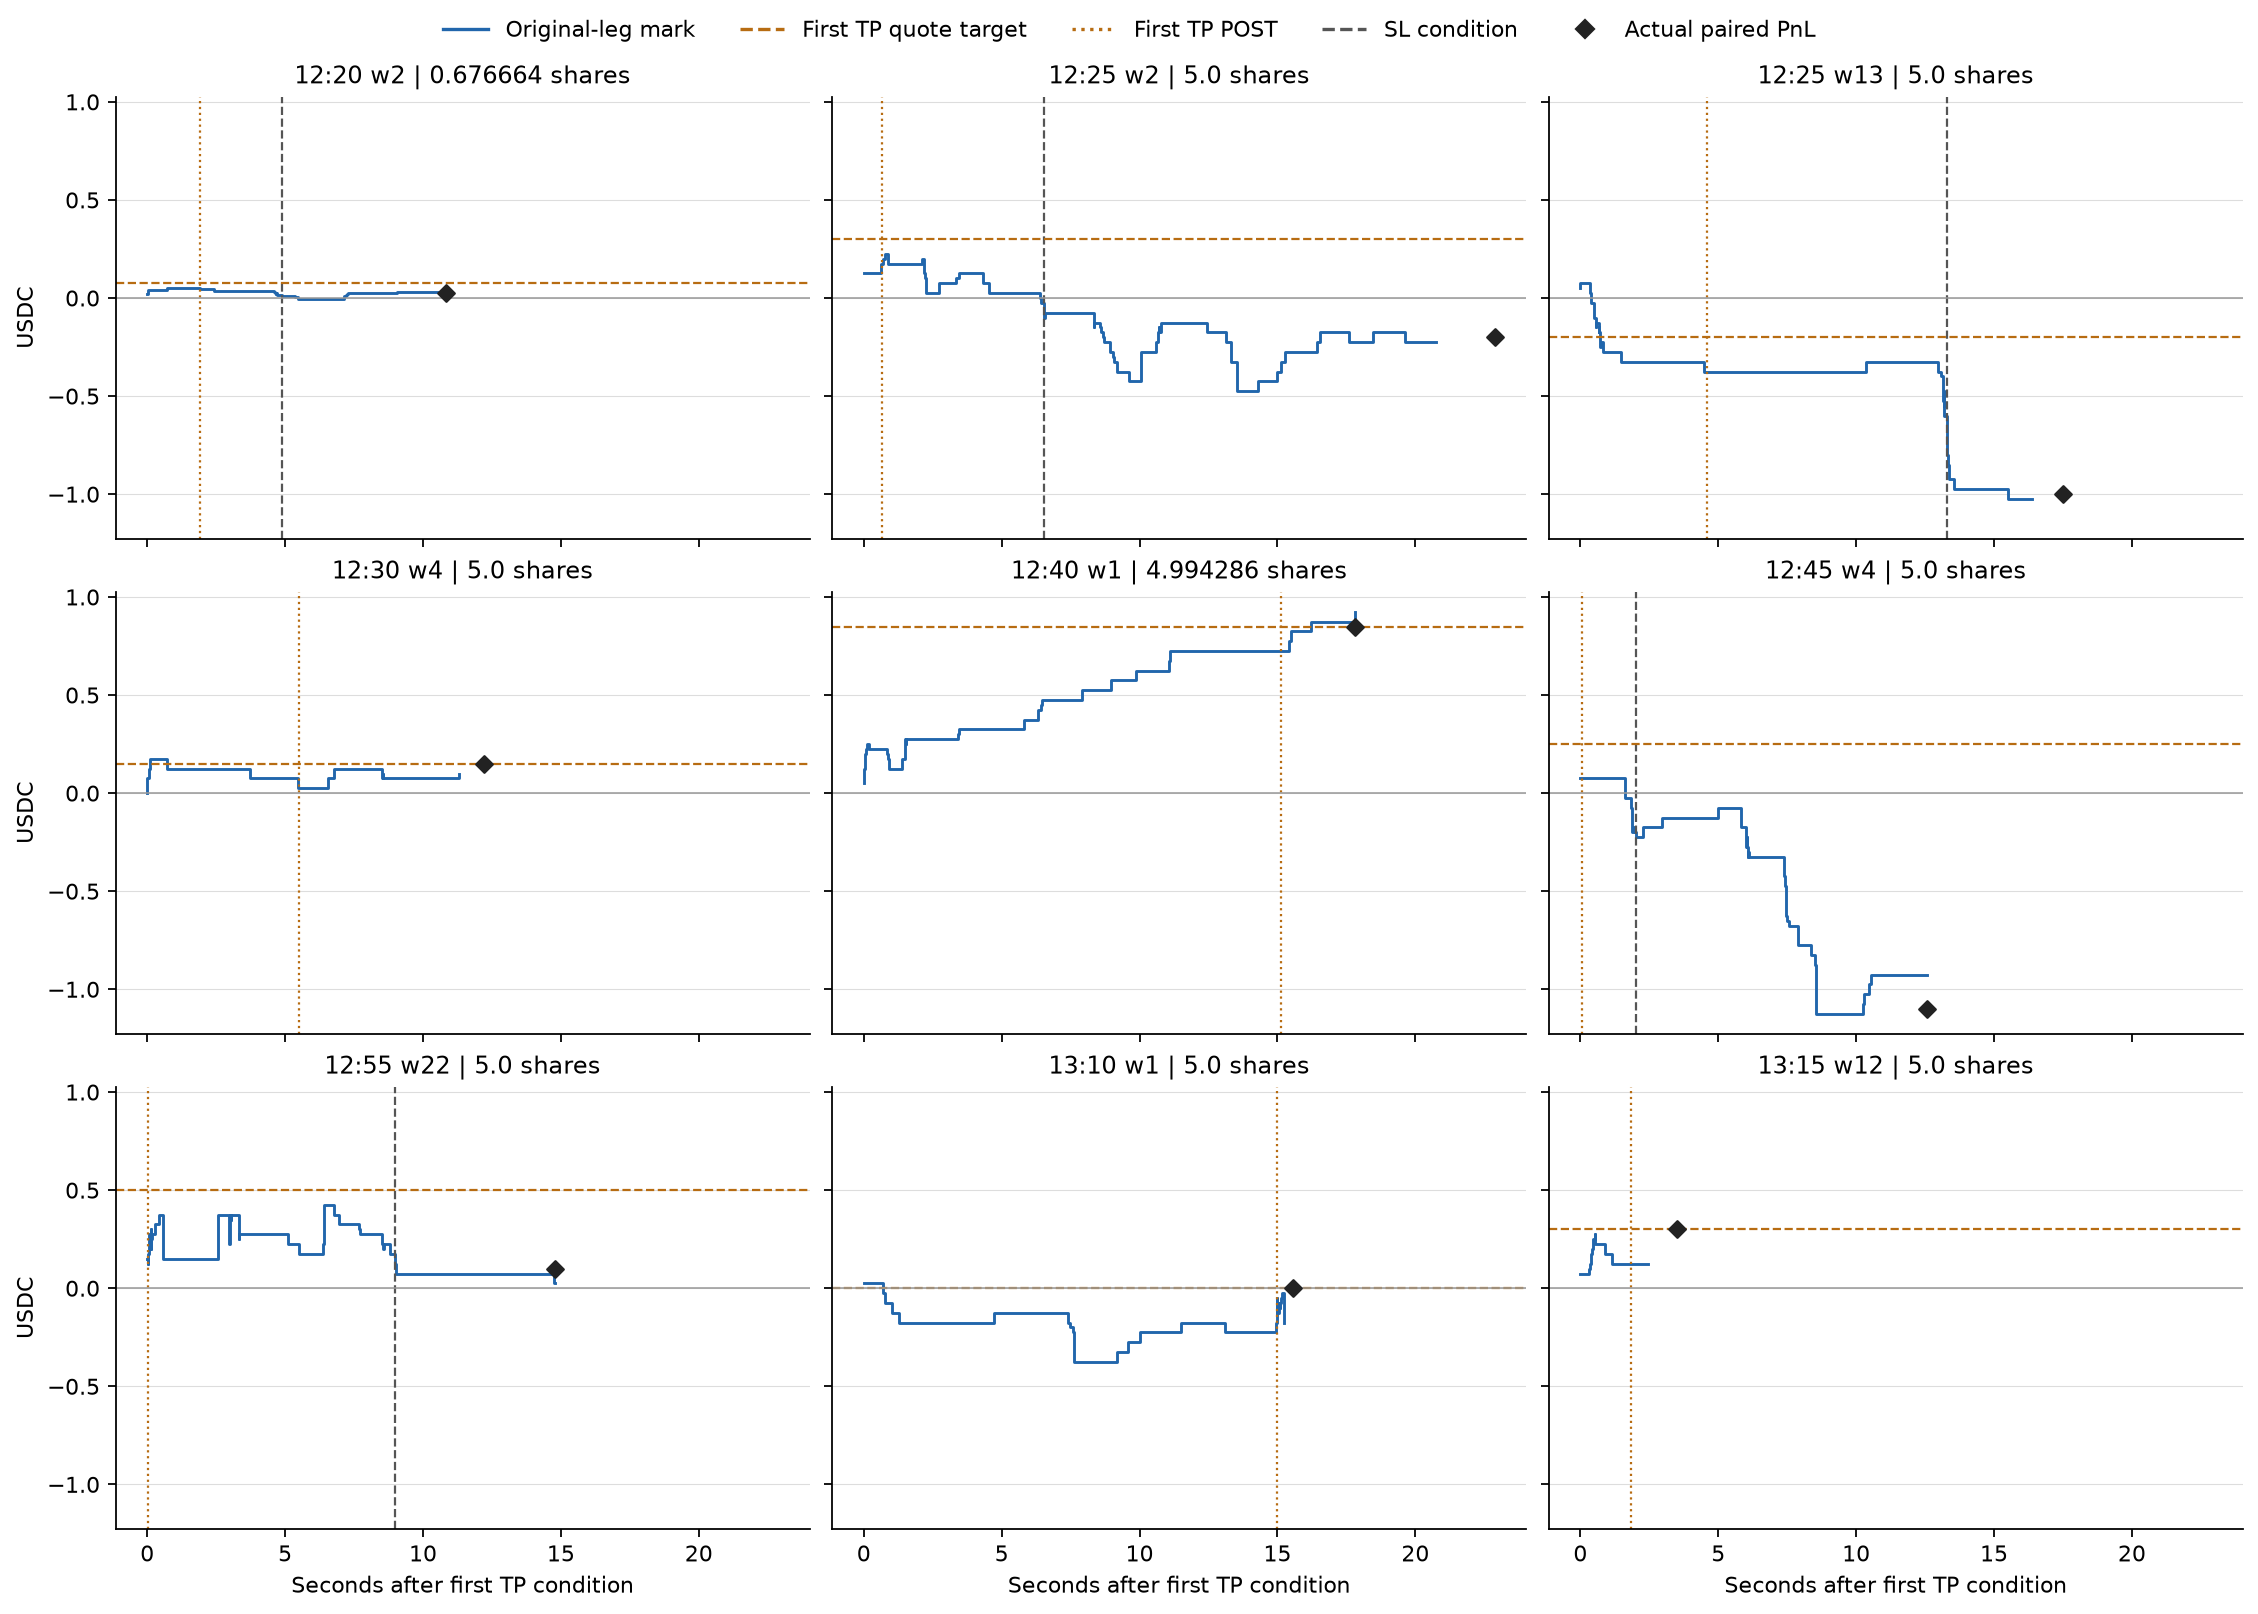

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
fig,axes=plt.subplots(3,3,figsize=(14,10),sharex=True,sharey=True,layout='constrained')
for ax,e in zip(axes.flat,tp):
    begin=e['first_tp']['projected_monotonic']
    points=sorted([p for p in paths if p['opening_window']==e['opening_window']],key=lambda p:p['projected_monotonic'])
    xs=[p['projected_monotonic']-begin for p in points]
    ys=[float(p['original_leg_mark_pnl']) for p in points]
    ax.step(xs,ys,where='post',color='#2166ac',linewidth=1.3)
    anchor=e['first_tp']['wall_elapsed_projection']
    ax.axvline(e['first_tp_post']['post_wall_elapsed']-anchor,color='#b76c12',linewidth=1,linestyle=':')
    if e['first_sl']:
        ax.axvline(e['first_sl']['wall_elapsed_projection']-anchor,color='#555555',linewidth=1,linestyle='--')
    target=float(e['first_tp_post']['paired_pnl_at_quote'])
    ax.axhline(target,color='#b76c12',linewidth=1,linestyle='--')
    ax.scatter(e['first_observed_repair_fill']['first_observed_elapsed']-anchor,float(e['actual_paired_pnl']),marker='D',s=28,color='#222222',zorder=4)
    ax.axhline(0,color='#999999',linewidth=.7)
    ax.grid(axis='y',color='#dddddd',linewidth=.5)
    ax.set_title(e['market']+' '+e['opening_window'].split(':')[-1]+' | '+e['original_quantity']+' shares',fontsize=11)
    ax.spines[['top','right']].set_visible(False)
    ax.tick_params(labelsize=10)
for ax in axes[-1]: ax.set_xlabel('Seconds after first TP condition',fontsize=10)
for ax in axes[:,0]: ax.set_ylabel('USDC',fontsize=10)
fig.legend(handles=[Line2D([],[],color='#2166ac',label='Original-leg mark'),Line2D([],[],color='#b76c12',linestyle='--',label='First TP quote target'),Line2D([],[],color='#b76c12',linestyle=':',label='First TP POST'),Line2D([],[],color='#555555',linestyle='--',label='SL condition'),Line2D([],[],color='#222222',marker='D',linestyle='none',label='Actual paired PnL')],loc='outside upper center',ncol=5,frameon=False,fontsize=10)
fig.savefig(OUT/'tp-paths.png',dpi=160,bbox_inches='tight')
from IPython.display import Image
display(Image(filename=str(OUT/'tp-paths.png')))
plt.close(fig)

## 验证与解释边界

峰值是事后诊断基准，不是可实现的反事实收益；Maker成交可能优于mid估值。原始5股中途部分成交时，全量开仓固定投影与当时实际数量不同。主表9轮TP已逐点核对记录估值，均在微美元容差内；直接SL控制组有一个开仓分笔锚点，保留为固定原始腿估值，不伪称实时全仓PnL。以下固定订单篮子的报价计算不假设真正会成交，也不模拟提前成交后新的NORMAL轮次。

In [4]:
tp_windows={e['opening_window'] for e in tp}
by={e['opening_window']:e for e in tp}
for p in paths:
    if p['opening_window'] not in tp_windows:continue
    q=D(by[p['opening_window']]['original_quantity'])
    assert abs(D(p['original_leg_mark_pnl'])-q*D(str(p['pnl_per_share'])))<D('.000001')
actual=sum((D(e['actual_paired_pnl']) for e in tp),D(0))
targets=sum((D(e['first_tp_post']['paired_pnl_at_quote']) for e in tp),D(0))
assert actual==D(s['stats']['tp_first_actual_paired_pnl'])
assert targets==D(s['stats']['first_tp_quote_fixed_basket_paired_pnl'])
print('Actual TP-first paired PnL:',actual,'\nFirst quote basket:',targets)
subset=[e for e in tp if e['first_sl']]
peak=sum((D(e['peak_original_leg_mark_before_sl']['original_leg_mark_pnl']) for e in subset),D(0))
sl=sum((D(e['first_sl']['mark_pnl']) for e in subset),D(0))
final=sum((D(e['actual_paired_pnl']) for e in subset),D(0))
assert peak-final==(peak-sl)+(sl-final)
print('TP->SL: peak marks',peak,'SL-trigger marks',sl,'actual paired',final)
print('Stage differences:',peak-sl,sl-final,'(diagnostic comparisons, not recoverable profit)')

Actual TP-first paired PnL: -0.87390492000 
First quote basket: 2.223461560000000000000000000
TP->SL: peak marks 0.850749800 SL-trigger marks -0.789850040 actual paired -2.17293344000
Stage differences: 1.640599840 1.38308340000 (diagnostic comparisons, not recoverable profit)
